# 08 · Extended October forecasting assessment

**Objective:** assess fixed forecasting candidates on additional mature October observations and
establish a bounded experimental point-forecast strategy. This is retrospective evidence using a
frozen publisher snapshot, not proof of production readiness or a point-in-time vintage reconstruction.

The candidate family is fixed: two weekly seasonal baselines, the existing direct/anchored models,
a same-weekday annual baseline and a fixed 50/50 annual/weekly blend. Candidate settings are not
changed after October scoring. Selection uses March-April 2026 only. Historical calibration begins
after selection labels are mature. The default experimental strategy is selected among inspectable
deterministic baselines; fitted models remain benchmarks.

Previously scored 5-11 October outcomes are identified separately. The primary additional sample
is 1-4 and 12-21 October. Source counts after 21 October are immature under the 14-complete-day
policy and are excluded. Earlier September outcomes are context, not new independent evidence.
The old forecast products and November registrations are preserved byte-for-byte.

In [1]:
from pathlib import Path
import sys,json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'scripts/extended_forecasting.py').exists())
sys.path.insert(0,str(ROOT/'scripts'))
from forecasting import load_inputs,make_examples,metrics,sha256,issue_cutoff
from forecast_intervals import load_snapshot,monitoring_view,interval_metrics
from extended_forecasting import add_annual_history,benchmark,rolling_intervals,CANDIDATES
BASE=ROOT/'data/processed/new_york'
OUT=BASE/'october_validation';REPORT=ROOT/'reports/october_validation'
OUT.mkdir(parents=True,exist_ok=True);(REPORT/'figures').mkdir(parents=True,exist_ok=True)
protected_files=[p for folder in ['forecasting','forecasting_followup','forecast_error_analysis','prospective_registry']
                 for p in (BASE/folder).rglob('*') if p.is_file()]
protected={p.relative_to(ROOT).as_posix():sha256(p) for p in protected_files}
SNAPSHOT='data/raw/new_york_monitoring/20261105T134740Z'
original,routes=load_inputs(ROOT)
latest,poll=load_snapshot(ROOT,SNAPSHOT)
combined,network=monitoring_view(original,latest,routes)
asof=pd.Timestamp(poll['observed_utc']).tz_convert('America/New_York').tz_localize(None).normalize()
score_cutoff=asof-pd.Timedelta(days=15)
selection_origins=pd.date_range('2026-03-02','2026-04-20',freq='W-MON')
warmup_origins=pd.date_range('2026-06-22','2026-08-24',freq='W-MON')
context_origins=pd.date_range('2026-08-31','2026-10-19',freq='W-MON')
all_origins=pd.date_range('2025-03-03','2026-10-19',freq='W-MON')
protocol={'candidates':CANDIDATES,'selection_last_target':'2026-04-26',
    'score_cutoff':str(score_cutoff.date()),'maturity_days':14,'annual_shift_days':364,
    'growth_window_days':28,'minimum_growth_pairs':14,'growth_ratio_limits':[.5,2.],
    'rolling_calibration_days':56,'residual_scale_floor':100,'interval_levels':[.8,.9],
    'interval_grouping':'weekday/Saturday/Sunday; global fallback below 100 residuals',
    'default_selection':'Lowest March-April MAE among four deterministic baselines',
    'october_retuning_allowed':False,'prospective_acceptance_claimed':False}
(OUT/'protocol.json').write_text(json.dumps(protocol,indent=2),encoding='utf-8')
assert selection_origins.max()+pd.Timedelta(days=6)<=issue_cutoff(warmup_origins.min(),14)
print('Protocol fixed before assessment; mature outcomes through:',score_cutoff.date())
display(pd.DataFrame([{'routes':len(routes),'available_october_route_dates':int(latest.payment_date.dt.month.eq(10).sum()),
    'mature_october_route_dates':int((latest.payment_date.dt.month.eq(10)&latest.payment_date.le(score_cutoff)).sum())}]))

Protocol fixed before assessment; mature outcomes through: 2026-10-21


,routes,available_october_route_dates,mature_october_route_dates
0,41,1107,861


## 1. Build annual predictors from information available at issue

Annual reference dates are exactly 364 days earlier, preserving weekday. A route-level growth ratio
compares sums across up to 28 released recent dates with their same-weekday prior-year dates.
Require at least 14 paired observations and a positive denominator; constrain the ratio to 0.5-2.0.
The ratio never uses a target date or observations after its availability cutoff. Fixed federal
holiday mismatches, unavailable annual counts or insufficient paired history fall back to the
weekly seasonal mean. Zero is preserved as an observed value, not interpreted as missing.

This is a prior-year demand proxy, not evidence that route definitions or agency calendars remained
identical. The source may contain publisher imputation/revisions; historical vintages are unavailable.

In [2]:
examples=add_annual_history(make_examples(combined,routes,all_origins,14),combined)
assert examples.annual_reference_date.le(examples.availability_cutoff).all()
display(examples.loc[examples.origin.eq(selection_origins.min()),['bus_route','payment_date','availability_cutoff',
    'annual_reference_date','annual_value','annual_growth_ratio','annual_growth_pair_count','annual_eligible','annual_scaled']].head(10))
print('Annual eligibility during selection:',round(100*examples.loc[examples.origin.isin(selection_origins),'annual_eligible'].mean(),2),'%')

,bus_route,payment_date,availability_cutoff,annual_reference_date,annual_value,annual_growth_ratio,annual_growth_pair_count,annual_eligible,annual_scaled
14924,M1,2026-03-02,2026-02-15,2025-03-03,7898.0,0.859709,28,True,6789.985347
14925,M10,2026-03-02,2026-02-15,2025-03-03,3275.0,0.794755,28,True,2602.824147
14926,M101,2026-03-02,2026-02-15,2025-03-03,15164.0,0.844383,28,True,12804.222337
14927,M102,2026-03-02,2026-02-15,2025-03-03,8979.0,0.795797,28,True,7145.463821
14928,M103,2026-03-02,2026-02-15,2025-03-03,6619.0,0.775849,28,True,5135.342188
14929,M104,2026-03-02,2026-02-15,2025-03-03,5297.0,0.834198,28,True,4418.746598
14930,M106,2026-03-02,2026-02-15,2025-03-03,1701.0,0.853478,28,True,1451.765972
14931,M11,2026-03-02,2026-02-15,2025-03-03,8496.0,0.874520,28,True,7429.922782
14932,M116,2026-03-02,2026-02-15,2025-03-03,5342.0,0.854212,28,True,4563.199317
14933,M12,2026-03-02,2026-02-15,2025-03-03,999.0,0.989242,28,True,988.252347


Annual eligibility during selection: 100.0 %


## 2. Select using earlier dates, then freeze the comparison

March-April target observations are used only for selection. The weekly seasonal mean remains the
fixed reference. The default strategy is selected from seasonal_latest, seasonal_mean4, annual_scaled
and annual_blend_50; all seven candidates are also ranked as research benchmarks. No October
result changes the selection. Historical source versions were not available at these simulated
issue times, so numerical cutoff discipline is not a claim of vintage-correct replay.

In [3]:
selection,selection_audit=benchmark(examples,selection_origins,CANDIDATES,score_cutoff)
selection_scores=metrics(selection).sort_values(['mae','model']).reset_index(drop=True)
deterministic=['seasonal_latest','seasonal_mean4','annual_scaled','annual_blend_50']
default_strategy=selection_scores.loc[selection_scores.model.isin(deterministic)].iloc[0].model
best_benchmark=selection_scores.iloc[0].model
print('Frozen experimental default:',default_strategy,'| best selection benchmark:',best_benchmark)
display(selection_scores.round(3))

2026-03-02: 14,104 training / 287 scored rows


2026-03-09: 14,391 training / 287 scored rows


2026-03-16: 14,678 training / 287 scored rows


2026-03-23: 14,965 training / 287 scored rows


2026-03-30: 15,252 training / 287 scored rows


2026-04-06: 15,539 training / 287 scored rows


2026-04-13: 15,826 training / 287 scored rows


2026-04-20: 16,113 training / 287 scored rows


Frozen experimental default: annual_blend_50 | best selection benchmark: anchored_ratio_15


,model,rows,routes,mae,rmse,wape,bias,actual_total
0,anchored_ratio_15,2296,41,465.789,726.648,0.084,-97.539,12722826.0
1,anchored_blend_50,2296,41,527.928,810.895,0.095,-267.334,12722826.0
2,boosted_15,2296,41,538.973,814.487,0.097,-144.878,12722826.0
3,annual_blend_50,2296,41,545.111,798.328,0.098,-317.509,12722826.0
4,annual_scaled,2296,41,549.679,831.957,0.099,-197.890,12722826.0
5,seasonal_mean4,2296,41,631.688,963.471,0.114,-437.128,12722826.0
6,seasonal_latest,2296,41,654.074,1199.889,0.118,-318.529,12722826.0


## 3. Generate released residuals and context forecasts

Warm-up predictions supply out-of-sample errors after the selection period. All point candidates
remain fixed; each fitted model refits only on targets at or before its issue cutoff. Later available
outcomes from an earlier assessment week may enter a subsequent fit or calibration, matching the
declared rolling workflow. No immature October target is scored or used for historical training.

The context contains eight issue dates, but the final origin has only three mature target dates.
It is not eight complete independent test weeks, and it is not prospective evidence.

In [4]:
interval_names=list(dict.fromkeys(['seasonal_mean4',default_strategy,'anchored_blend_50',best_benchmark]))
warmup,warmup_audit=benchmark(examples,warmup_origins,interval_names,score_cutoff)
context,context_audit=benchmark(examples,context_origins,CANDIDATES,score_cutoff)
display(context_audit)
print('Context route/dates per candidate:',int(context.groupby('model').size().min()))

2026-06-22: 18,696 training / 287 scored rows


2026-06-29: 18,983 training / 287 scored rows


2026-07-06: 19,270 training / 287 scored rows


2026-07-13: 19,557 training / 287 scored rows


2026-07-20: 19,844 training / 287 scored rows


2026-07-27: 20,131 training / 287 scored rows


... (10 outputs left out)

2026-10-12: 23,247 training / 287 scored rows


2026-10-19: 23,534 training / 123 scored rows


,origin,cutoff,train_rows,last_training_target,target_rows,target_dates,complete_week
0,2026-08-31,2026-08-16,21525,2026-08-15,287,7,True
1,2026-09-07,2026-08-23,21812,2026-08-23,287,7,True
2,2026-09-14,2026-08-30,22099,2026-08-30,287,7,True
3,2026-09-21,2026-09-06,22386,2026-09-06,287,7,True
4,2026-09-28,2026-09-13,22673,2026-09-13,287,7,True
5,2026-10-05,2026-09-20,22960,2026-09-20,287,7,True
6,2026-10-12,2026-09-27,23247,2026-09-27,287,7,True
7,2026-10-19,2026-10-04,23534,2026-10-04,123,3,False


Context route/dates per candidate: 2132


## 4. Separate new October evidence from previously scored outcomes

All mature October observations are scored, but the primary additional sample excludes the
5-11 October outcomes already evaluated in notebook 06. Comparisons use identical route/date
populations. Report route/week errors and real zero counts as well as pooled MAE/WAPE. Do not
compare these 14-day rolling results directly with the old, differently timed seven-day outlook.

In [5]:
october=context.loc[context.payment_date.ge('2026-10-01')].copy()
old=pd.read_csv(BASE/'forecasting_followup/later_outcome_predictions.csv',dtype={'bus_route':'string'},parse_dates=['payment_date'])
old_keys=old[['bus_route','payment_date']].drop_duplicates().assign(previously_scored=True)
october=october.merge(old_keys,how='left',on=['bus_route','payment_date'],validate='many_to_one')
additional=october.loc[october.previously_scored.isna()].copy()
all_october_scores=metrics(october)
additional_scores=metrics(additional).sort_values('mae').reset_index(drop=True)
route_scores=metrics(additional,('model','bus_route'))
week_scores=metrics(additional,('model','origin'))
assert additional.groupby('model').size().nunique()==1
assert additional.groupby('model').size().iloc[0]==574
assert october.groupby('model').size().iloc[0]==861
assert not additional.payment_date.between('2026-10-05','2026-10-11').any()
display(additional_scores.round(3))
print('All mature October results, including previously examined dates:')
display(all_october_scores.round(3))
display(week_scores.loc[week_scores.model.isin(['seasonal_mean4',default_strategy])].round(3))

,model,rows,routes,mae,rmse,wape,bias,actual_total
0,boosted_15,574,41,597.556,953.924,0.098,-368.846,3514094.0
1,anchored_ratio_15,574,41,631.833,988.344,0.103,-530.378,3514094.0
2,anchored_blend_50,574,41,636.084,973.597,0.104,-510.471,3514094.0
3,seasonal_latest,574,41,643.556,1102.954,0.105,-353.713,3514094.0
4,seasonal_mean4,574,41,669.345,1024.665,0.109,-490.564,3514094.0
5,annual_blend_50,574,41,697.335,1065.966,0.114,-607.064,3514094.0
6,annual_scaled,574,41,805.810,1226.249,0.132,-723.564,3514094.0


All mature October results, including previously examined dates:


,model,rows,routes,mae,rmse,wape,bias,actual_total
0,anchored_blend_50,861,41,668.677,994.642,0.109,-544.154,5304043.0
1,anchored_ratio_15,861,41,654.194,985.913,0.106,-542.715,5304043.0
2,annual_blend_50,861,41,715.448,1067.003,0.116,-633.481,5304043.0
3,annual_scaled,861,41,795.620,1187.995,0.129,-721.369,5304043.0
4,boosted_15,861,41,548.861,874.744,0.089,-225.698,5304043.0
5,seasonal_latest,861,41,578.714,991.292,0.094,-216.612,5304043.0
6,seasonal_mean4,861,41,704.408,1052.907,0.114,-545.593,5304043.0


,model,origin,rows,routes,mae,rmse,wape,bias,actual_total
6,annual_blend_50,2026-09-28,164,41,994.476,1403.393,0.172,-961.748,949065.0
7,annual_blend_50,2026-10-12,287,41,553.655,832.873,0.093,-428.943,1709127.0
8,annual_blend_50,2026-10-19,123,41,636.397,1028.620,0.091,-549.768,855902.0
18,seasonal_mean4,2026-09-28,164,41,934.841,1314.336,0.162,-825.037,949065.0
19,seasonal_mean4,2026-10-12,287,41,539.218,807.058,0.091,-287.138,1709127.0
20,seasonal_mean4,2026-10-19,123,41,618.980,1037.599,0.089,-519.264,855902.0


## 5. Adapt interval calibration using released errors

The interval method is fixed before scoring: signed residual quantiles over the most recent
56 released target dates, normalized by max(the issued point prediction, 100). Weekdays, Saturdays
and Sundays are separate groups, falling back to the global pool below 100 residuals. Bounds are
clipped to zero. No future residual is used. These are empirical intervals, with no exchangeability
or prospective coverage guarantee. Report both coverage and interval score so excessive width
cannot be mistaken for success.

In [6]:
residual_predictions=pd.concat([warmup,context.loc[context.model.isin(interval_names)]],ignore_index=True)
rolling,calibration_audit=rolling_intervals(residual_predictions,context_origins,score_cutoff)
october_intervals=rolling.loc[rolling.payment_date.ge('2026-10-01')].merge(old_keys,
    how='left',on=['bus_route','payment_date'],validate='many_to_one')
additional_intervals=october_intervals.loc[october_intervals.previously_scored.isna()]
coverage=interval_metrics(additional_intervals,('model','level'))
all_coverage=interval_metrics(october_intervals,('model','level'))
weekly_coverage=interval_metrics(additional_intervals,('model','level','origin'))
assert calibration_audit.last_calibration_target.le(calibration_audit.available_cutoff).all()
display(coverage.round(3))
display(weekly_coverage.loc[weekly_coverage.level.eq(.9)].round(3))
display(calibration_audit.head(8))

,model,level,rows,coverage,mean_width,mean_interval_score
0,anchored_blend_50,0.8,574,0.760,2046.708,2989.949
1,anchored_blend_50,0.9,574,0.876,2764.120,3551.781
2,anchored_ratio_15,0.8,574,0.742,1865.915,3038.044
3,anchored_ratio_15,0.9,574,0.845,2562.235,3767.745
4,annual_blend_50,0.8,574,0.749,1829.127,2938.231
5,annual_blend_50,0.9,574,0.852,2541.808,3627.203
6,seasonal_mean4,0.8,574,0.760,2286.713,3252.610
7,seasonal_mean4,0.9,574,0.871,3141.302,3814.086


,model,level,origin,rows,coverage,mean_width,mean_interval_score
3,anchored_blend_50,0.9,2026-09-28,164,0.695,2301.928,4663.616
4,anchored_blend_50,0.9,2026-10-12,287,0.934,2850.406,3059.246
5,anchored_blend_50,0.9,2026-10-19,123,0.984,3179.041,3218.584
9,anchored_ratio_15,0.9,2026-09-28,164,0.689,2226.215,4687.616
10,anchored_ratio_15,0.9,2026-10-12,287,0.875,2605.364,3592.487
11,anchored_ratio_15,0.9,2026-10-19,123,0.984,2909.628,2950.187
15,annual_blend_50,0.9,2026-09-28,164,0.640,2137.161,5479.733
16,annual_blend_50,0.9,2026-10-12,287,0.934,2626.843,2782.851
17,annual_blend_50,0.9,2026-10-19,123,0.943,2882.925,3127.318
21,seasonal_mean4,0.9,2026-09-28,164,0.707,2538.620,4287.680


,model,origin,level,day_group,available_cutoff,calibration_rows,last_calibration_target,first_calibration_target,global_fallback,lower_quantile,upper_quantile
0,anchored_blend_50,2026-08-31,0.8,0,2026-08-16,1640,2026-08-14,2026-06-22,False,-0.148346,0.114521
1,anchored_blend_50,2026-08-31,0.9,0,2026-08-16,1640,2026-08-14,2026-06-22,False,-0.196048,0.178311
2,anchored_blend_50,2026-08-31,0.8,5,2026-08-16,328,2026-08-15,2026-06-27,False,-0.260970,0.205879
3,anchored_blend_50,2026-08-31,0.9,5,2026-08-16,328,2026-08-15,2026-06-27,False,-0.328550,0.311758
4,anchored_blend_50,2026-08-31,0.8,6,2026-08-16,287,2026-08-09,2026-06-28,False,-0.197586,0.270482
5,anchored_blend_50,2026-08-31,0.9,6,2026-08-16,287,2026-08-09,2026-06-28,False,-0.318857,0.409950
6,anchored_blend_50,2026-09-07,0.8,0,2026-08-23,1640,2026-08-21,2026-06-29,False,-0.145941,0.119153
7,anchored_blend_50,2026-09-07,0.9,0,2026-08-23,1640,2026-08-21,2026-06-29,False,-0.194487,0.182729


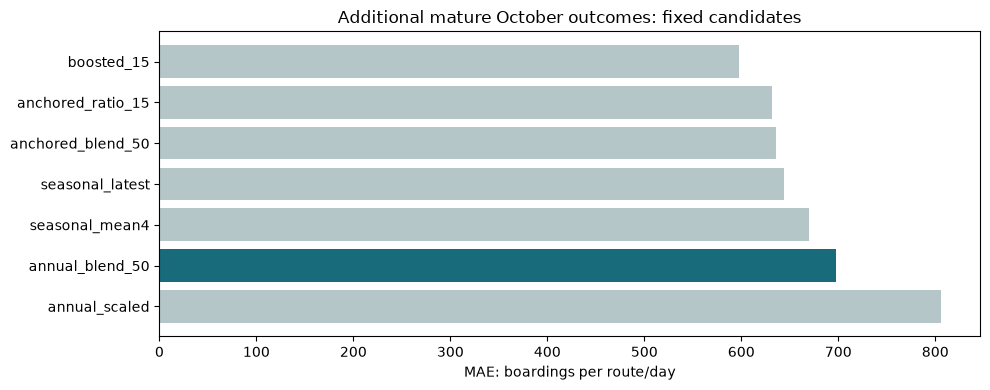

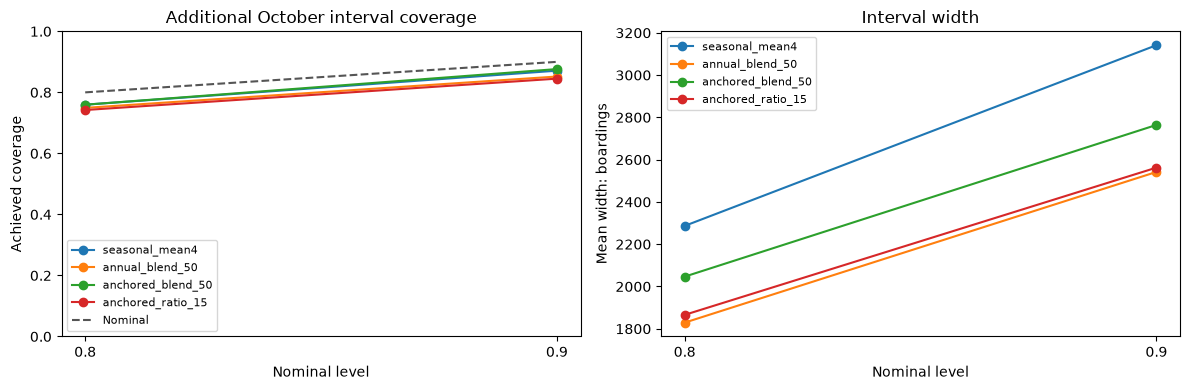

In [7]:
def save_figure(name):
    plt.tight_layout();plt.savefig(REPORT/'figures'/f'{name}.png',dpi=160,bbox_inches='tight');plt.show()
fig,ax=plt.subplots(figsize=(10,4))
table=additional_scores.sort_values('mae')
ax.barh(table.model,table.mae,color=['#176b7a' if name==default_strategy else '#b5c6c9' for name in table.model])
ax.invert_yaxis();ax.set(title='Additional mature October outcomes: fixed candidates',xlabel='MAE: boardings per route/day')
save_figure('additional_october_mae')
fig,axes=plt.subplots(1,2,figsize=(12,4))
for name in interval_names:
    part=coverage.loc[coverage.model.eq(name)]
    axes[0].plot(part.level,part.coverage,marker='o',label=name)
    axes[1].plot(part.level,part.mean_width,marker='o',label=name)
axes[0].plot([.8,.9],[.8,.9],ls='--',color='#555555',label='Nominal')
axes[0].set(ylim=(0,1),title='Additional October interval coverage',xlabel='Nominal level',ylabel='Achieved coverage')
axes[1].set(title='Interval width',xlabel='Nominal level',ylabel='Mean width: boardings')
for ax in axes:ax.set_xticks([.8,.9]);ax.legend(fontsize=8)
save_figure('rolling_interval_coverage')

## 6. Make the experimental-use decision

The deterministic default was selected before assessment. A usable research feature must preserve
source identity, respect availability, compare with the fixed reference, report failures and withhold
forecasts when data is insufficient. No retrospective result overrides the existing prospective
acceptance policy. Bands outside nominal +/-5 percentage points on the primary sample are marked
not validated and must not be presented as reliable confidence claims.

The extra sample is only 14 target dates across parts of three issue weeks. This can strengthen a
historical prototype, but cannot establish robust operational reliability. No further tuning on
these October outcomes is performed.

The deterministic selection is a proposal, not an automatic deployment choice. The preview
keeps the existing seasonal mean as its default and exposes the best earlier selection benchmark
only as an optional experimental challenger. A poorer annual proposal is retained as a reported
negative result. The challenger is not chosen by ranking October assessment scores.

In [8]:
default_row=additional_scores.loc[additional_scores.model.eq(default_strategy)].iloc[0]
reference_row=additional_scores.loc[additional_scores.model.eq('seasonal_mean4')].iloc[0]
gain=100*(1-default_row.mae/reference_row.mae)
decision={'mode':'experimental_historical_forecasting','default_strategy':default_strategy,
    'selection_basis':'March-April 2026 MAE among deterministic baselines',
    'additional_october_rows':int(default_row.rows),'additional_october_mae':float(default_row.mae),
    'reference_mae':float(reference_row.mae),'mae_improvement_percent':float(gain),
    'operationally_accepted':False,'prospective_policy_unchanged':True,
    'intervals':[{**row,'within_5_percentage_points':bool(abs(row['coverage']-row['level'])<=.05)}
        for row in coverage.loc[coverage.model.eq(default_strategy)].to_dict(orient='records')]}
display(pd.DataFrame([{'mode':decision['mode'],'default':default_strategy,'MAE':default_row.mae,
    'baseline_MAE':reference_row.mae,'relative_MAE_improvement_percent':gain}]).round(3))
display(pd.DataFrame(decision['intervals']).round(3))
print('No candidate or interval setting is changed after these scores. Original registrations remain authoritative.')

,mode,default,MAE,baseline_MAE,relative_MAE_improvement_percent
0,experimental_historical_forecasting,annual_blend_50,697.335,669.345,-4.182


,model,level,rows,coverage,mean_width,mean_interval_score,within_5_percentage_points
0,annual_blend_50,0.8,574,0.749,1829.127,2938.231,False
1,annual_blend_50,0.9,574,0.852,2541.808,3627.203,True


No candidate or interval setting is changed after these scores. Original registrations remain authoritative.


In [9]:
products={'selection_predictions':selection,'selection_scores':selection_scores,'selection_audit':selection_audit,
    'warmup_predictions':warmup,'warmup_audit':warmup_audit,'context_predictions':context,'context_audit':context_audit,
    'october_predictions':october,'additional_october_predictions':additional,
    'all_october_scores':all_october_scores,'additional_october_scores':additional_scores,
    'route_scores':route_scores,'week_scores':week_scores,'rolling_intervals':rolling,
    'calibration_audit':calibration_audit,'additional_october_intervals':additional_intervals,
    'interval_coverage':coverage,'all_october_interval_coverage':all_coverage,'weekly_interval_coverage':weekly_coverage}
for name,frame in products.items():frame.to_csv(OUT/f'{name}.csv',index=False)
assert protected=={p.relative_to(ROOT).as_posix():sha256(p) for p in protected_files}
summary={'snapshot':SNAPSHOT,'source_maturity_cutoff':str(score_cutoff.date()),'decision':decision,
    'selection_best_benchmark':best_benchmark,'selection_last_target':'2026-04-26',
    'assessment_first_context_origin':'2026-08-31','assessment_last_target':str(score_cutoff.date()),
    'additional_rows_per_candidate':574,'all_mature_october_rows_per_candidate':861,
    'additional_target_dates':14,'known_october_rows_per_candidate':287,
    'all_scores':additional_scores.to_dict(orient='records'),'coverage':coverage.to_dict(orient='records'),
    'protected_files_verified':len(protected),'november_registrations_unchanged':True,
    'prospective_acceptance_claimed':False,'october_retuning_performed':False}
manifest={'summary':summary,'protocol':protocol,'protocol_sha256':sha256(OUT/'protocol.json'),
    'protected_files':protected,'snapshot_source_hash':sha256(ROOT/SNAPSHOT/'route_days.csv'),
    'products':{name:{'rows':len(frame),'sha256':sha256(OUT/f'{name}.csv')} for name,frame in products.items()}}
(OUT/'october_manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
(REPORT/'summary.json').write_text(json.dumps(summary,indent=2),encoding='utf-8')
strategies={}
for name in dict.fromkeys(['seasonal_mean4',best_benchmark]):
    score=additional_scores.loc[additional_scores.model.eq(name)].iloc[0].to_dict()
    ranges=[{**row,'within_5_percentage_points':bool(abs(row['coverage']-row['level'])<=.05)}
        for row in coverage.loc[coverage.model.eq(name)].to_dict(orient='records')]
    strategies[name]={'primary_historical_scores':score,'intervals':ranges}
profile={'mode':'experimental_preview','reference_strategy':'seasonal_mean4',
    'challenger_strategy':best_benchmark,'challenger_selection':'Lowest March-April 2026 MAE across fixed candidates',
    'deterministic_proposal':default_strategy,'proposal_beats_reference_on_additional_october':bool(gain>0),
    'strategies':strategies,'operationally_accepted':False,'prospective_acceptance_claimed':False}
(OUT/'experimental_profile.json').write_text(json.dumps(profile,indent=2),encoding='utf-8')
manifest['experimental_profile']=profile
manifest['experimental_profile_sha256']=sha256(OUT/'experimental_profile.json')
(OUT/'october_manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
display(pd.DataFrame([{'preview_mode':'reference','strategy':'seasonal_mean4'},
    {'preview_mode':'challenger','strategy':best_benchmark}]))
print('Saved',len(products),'tables, two figures, frozen protocol and experimental profile.')
print('Existing forecasts and registrations verified unchanged.')

,preview_mode,strategy
0,reference,seasonal_mean4
1,challenger,anchored_ratio_15


Saved 19 tables, two figures, frozen protocol and experimental profile.
Existing forecasts and registrations verified unchanged.


## Final interpretation and supported use

The additional mature October sample contains **574 route/date observations**. The best candidate
selected on earlier dates, **anchored_ratio_15**, has MAE **631.83** versus reference **669.34**,
a **5.60% reduction**, with WAPE **10.32%** versus **10.93%**. The direct boosted model is lower
on October, but is not chosen after looking at assessment scores.

The earlier-selected deterministic proposal, **annual_blend_50**, is worse than the reference
(MAE **697.33**) and is not promoted. The final preview keeps **seasonal_mean4** as default and
offers the earlier-selected anchored model only as an experimental challenger.

Reference nominal 80%/90% ranges cover **75.96% / 87.11%** of the primary sample. Challenger
coverage is **74.22% / 84.49%**, outside the declared display tolerance, so challenger ranges
are withheld. None of these small-sample historical results establishes prospective reliability.

The guarded component is sufficient for a labelled experimental research preview. It is not
accepted for operational decisions. Commands from the repository root:

```powershell
python scripts/forecast_preview.py --mode reference
python scripts/forecast_preview.py --mode challenger
python scripts/audit_october_forecasting.py
```

Both preview modes save point forecasts, source/code fingerprints and uncertainty status locally.
The 5 November examples cover **6-12 November**, with history through **21 October**. They are
not replacement registrations. Original November forecasts and the prospective policy remain
unchanged. See [October assessment](../../documentation/OCTOBER_VALIDATION.md).